# Simple CNN for CHL under clouds: results

Runs live in `models/<run>/` (trained with `python -m chl_cnn.train`). All runs share the same 2020 subset
(32°N–5°S, 45–90°E), the same 70/20/10 chronological split and the same fixed fake-cloud pixels on the val/test days.
Scores are in ln(CHL) units on **hidden pixels**: observed on that day, cloudy on a donor day.

| run | inputs | loss pixels |
|---|---|---|
| `baseline_asis` | sst, so | every pixel, NaN→0 (as published) |
| `baseline_sst_so` | sst, so | observed L3 pixels |
| `chl_in_fakeclouds` | sst, so, ln CHL with fake clouds, observed flag | fake-cloud-hidden pixels |

Reference: per-pixel training-period mean ln CHL ("climatology"). The L4 gap-free product equals L3 on observed pixels, so it cannot be scored on hidden pixels.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from chl_cnn import data as D, plotting as P
from chl_cnn.evaluate import metrics, mae_by_bin

from chl_cnn.runs import find_run
RUNS = ["baseline_asis", "baseline_sst_so", "chl_in_fakeclouds"]
d = D.build_subset(verbose=False)
y = D.log_chl(d["chl_l3"])
obs = np.isfinite(y) & d["ocean"]
tr, va, te = D.split_indices(len(d["time"]))
dates = pd.to_datetime(d["time"])
cfg = {r: json.load(open(find_run(r) / "config.json")) for r in RUNS}
met = {r: json.load(open(find_run(r) / "metrics.json")) for r in RUNS}
hist = {r: json.load(open(find_run(r) / "history.json")) for r in RUNS}
pr = {r: np.load(find_run(r) / "preds.npz") for r in RUNS}
hid_te = pr[RUNS[0]]["hidden"][len(va) :]  # same for all runs
pred_te = {r: pr[r]["pred"][len(va) :] for r in RUNS}
clim = np.nanmean(y[tr], axis=0)
print(
    "days train/val/test:",
    len(tr),
    len(va),
    len(te),
    "| test:",
    dates[te][0].date(),
    "->",
    dates[te][-1].date(),
)

days train/val/test: 256 73 37 | test: 2020-11-25 -> 2020-12-31


## Test scores on hidden pixels

In [2]:
rows = []
for r in RUNS:
    s = met[r]["scores"]["test"]
    rows.append(
        dict(
            run=r,
            mae=s["cnn_hidden"]["mae"],
            rmse=s["cnn_hidden"]["rmse"],
            bias=s["cnn_hidden"]["bias"],
            r=s["cnn_hidden"]["r"],
            best_epoch=cfg[r]["best_epoch"],
            n_pixels=s["cnn_hidden"]["n"],
        )
    )
s = met[RUNS[0]]["scores"]["test"]["climatology_hidden"]
rows.append(
    dict(
        run="climatology (train mean)",
        mae=s["mae"],
        rmse=s["rmse"],
        bias=s["bias"],
        r=s["r"],
        best_epoch=None,
        n_pixels=s["n"],
    )
)
pd.DataFrame(rows).round(3)

,run,mae,rmse,bias,r,best_epoch,n_pixels
0,baseline_asis,1.615,1.701,1.580,0.019,16.0,132893
1,baseline_sst_so,0.278,0.409,0.046,0.753,33.0,132893
2,chl_in_fakeclouds,0.195,0.316,-0.023,0.857,50.0,132893
3,climatology (train mean),0.357,0.450,-0.209,0.781,NaN,132893


## Training curves

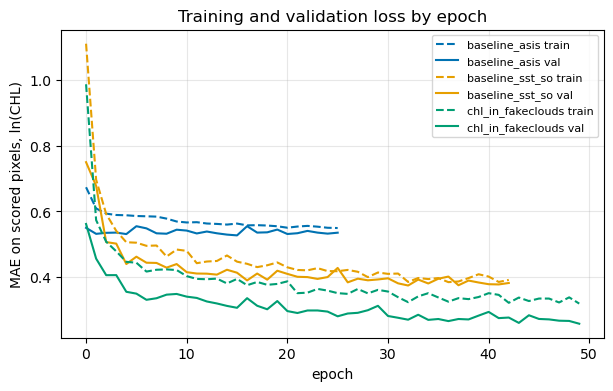

In [3]:
P.plot_history({r: hist[r] for r in RUNS})
plt.show()

## Daily MAE on hidden test pixels

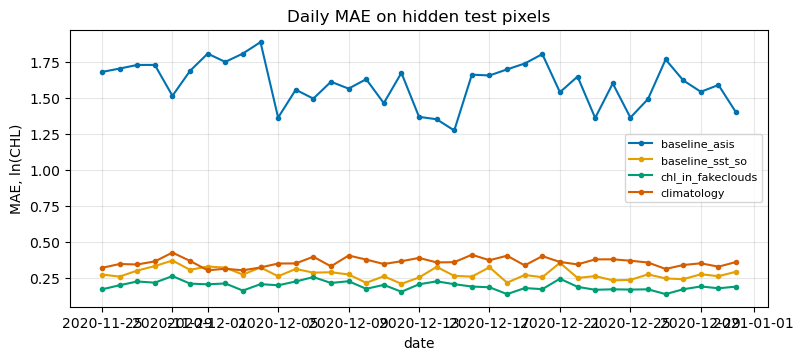

,mean,min,max
baseline_asis,1.598,1.274,1.887
baseline_sst_so,0.279,0.210,0.371
chl_in_fakeclouds,0.196,0.138,0.264
climatology,0.359,0.304,0.427


In [4]:
daily = {r: np.array([m["mae"] for m in met[r]["per_day_test"]]) for r in RUNS}
daily["climatology"] = np.array(
    [metrics(y[i], clim, hid_te[k])["mae"] for k, i in enumerate(te)]
)
P.plot_daily_mae(dates[te], daily)
plt.show()
pd.DataFrame(
    {k: pd.Series(v).describe()[["mean", "min", "max"]] for k, v in daily.items()}
).T.round(3)

## Predicted vs true, and MAE by CHL level

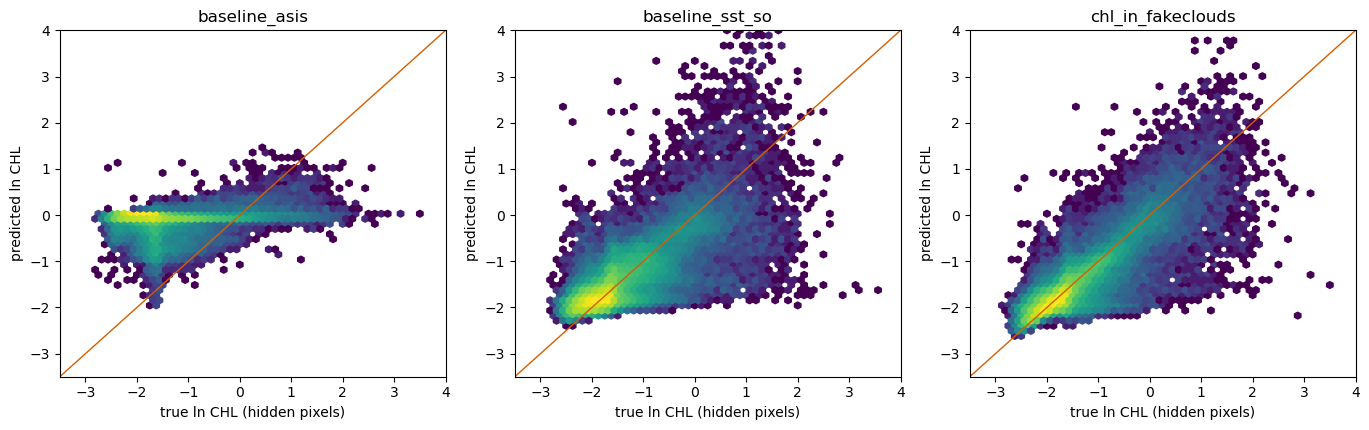

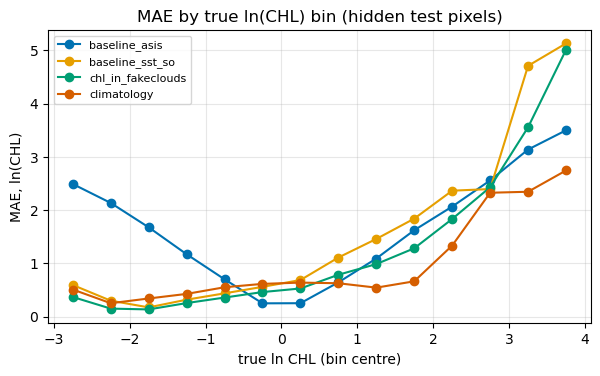

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
bin_centre,-3.25,-2.75,-2.25,-1.75,-1.25,-0.75,-0.25,0.25,0.75,1.25,1.75,2.25,2.75,3.25,3.75
n_pixels,0.00,924.00,35145.00,65231.00,16711.00,7401.00,3542.00,2023.00,1018.00,624.00,226.00,37.00,8.00,2.00,1.00


In [5]:
fig, axes = plt.subplots(1, len(RUNS), figsize=(4.6 * len(RUNS), 4.4))
for ax, r in zip(axes, RUNS):
    P.plot_scatter(y[te], pred_te[r], hid_te, r, ax=ax)
fig.tight_layout()
plt.show()
edges = np.arange(-3.5, 4.01, 0.5)
bins = {r: mae_by_bin(y[te], pred_te[r], hid_te, edges) for r in RUNS}
bins["climatology"] = mae_by_bin(
    y[te], np.broadcast_to(clim, y[te].shape), hid_te, edges
)
P.plot_mae_by_bin(bins)
plt.show()
pd.DataFrame(
    {"bin_centre": bins[RUNS[0]][0], "n_pixels": bins[RUNS[0]][2].astype(int)}
).T

## Example test days
Input CHL is what the cloud-filling model sees (observed minus fake clouds). Errors are shown on hidden pixels only.

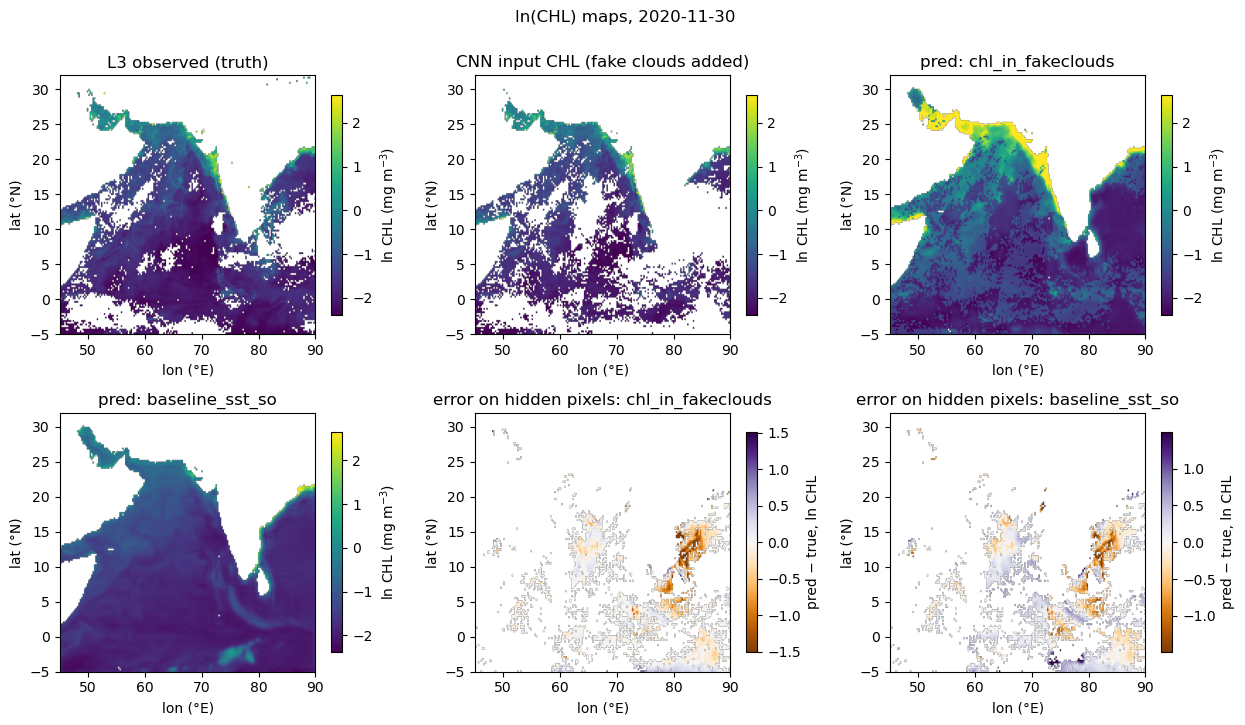

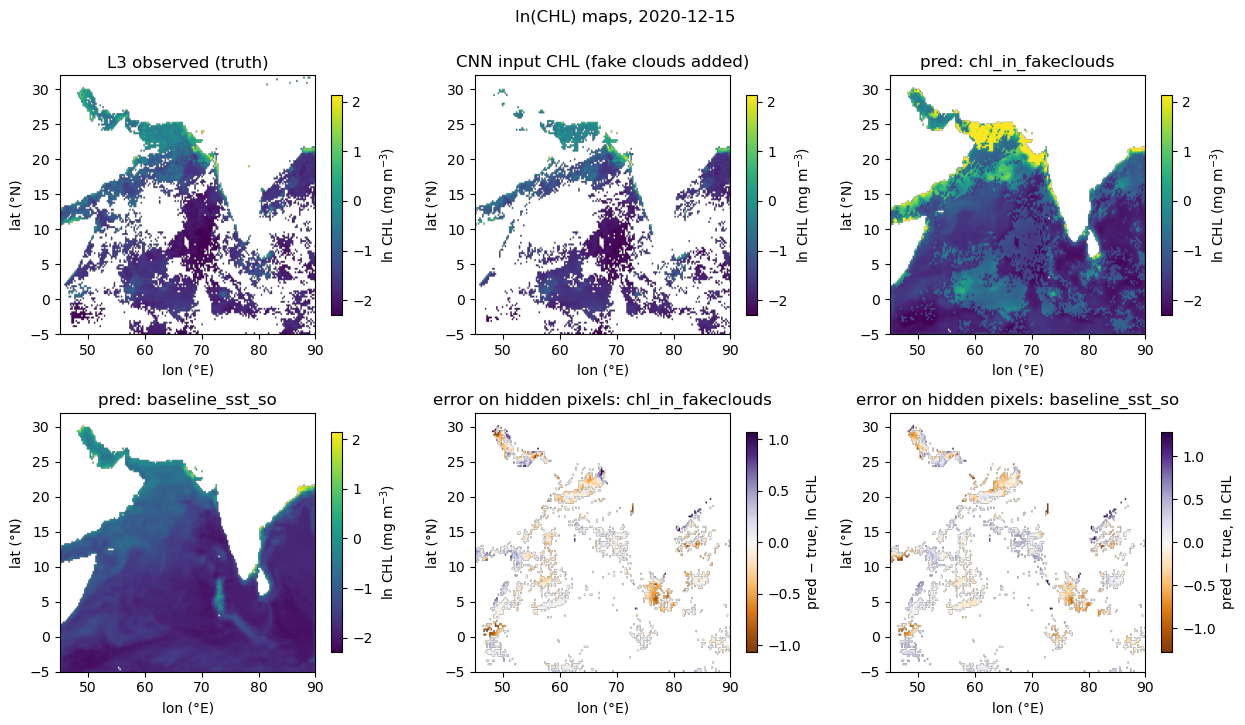

In [6]:
for k in [5, 20]:
    i = te[k]
    date = dates[i].date()
    inp = np.where(obs[i] & ~hid_te[k], y[i], np.nan)
    panels = {
        "L3 observed (truth)": y[i],
        "CNN input CHL (fake clouds added)": inp,
        "pred: chl_in_fakeclouds": pred_te["chl_in_fakeclouds"][k],
        "pred: baseline_sst_so": pred_te["baseline_sst_so"][k],
    }
    err = {
        f"error on hidden pixels: {r}": np.where(
            hid_te[k], pred_te[r][k] - y[i], np.nan
        )
        for r in ["chl_in_fakeclouds", "baseline_sst_so"]
    }
    P.plot_day_maps(d["lat"], d["lon"], panels, date, err=err, ncols=3)
    plt.show()

# Full period 1997–2020: all days vs clear days with clouds added

Same region and CNN, trained on Sept 1997 – Dec 2020 (`so` is missing after 2020). Inputs: sst, so, ln CHL with fake clouds, observed flag.
Split is **year-interleaved** (val years 2001, 2007, 2013, 2018; test years 2004, 2010, 2016, 2020; the rest train) because
CHL coverage rises from ~13% of ocean pixels in 1997 to ~53% in 2020, so a chronological split would leave no clear day for training.

| run | training days | loss pixels |
|---|---|---|
| `full_alldays_fakeclouds` | all 5,540 train days | fake-cloud-hidden pixels |
| `full_clear_fakeclouds` | the 152 train days with ≥60% of ocean pixels observed, fake clouds added | all observed pixels (near-complete label) |

Both runs are early-stopped on hidden-pixel val MAE and scored on the same fixed hidden test pixels.

In [7]:
FRUNS = ["full_alldays_fakeclouds", "full_clear_fakeclouds"]
fcfg = {r: json.load(open(find_run(r) / "config.json")) for r in FRUNS}
fmet = {r: json.load(open(find_run(r) / "metrics.json")) for r in FRUNS}
fhist = {r: json.load(open(find_run(r) / "history.json")) for r in FRUNS}
fpr = {r: np.load(find_run(r) / "preds.npz") for r in FRUNS}
full = np.load(D.cache_path(("1997-09-01", "2020-12-31"), ("sst", "so")))   # lazy per key
ftime = pd.to_datetime(full["time"]); focean = full["ocean"]
ftr, fva, fte = D.split_by_years(full["time"])
fy_te = D.log_chl(full["chl_l3"][fte]); fobs_te = np.isfinite(fy_te) & focean
fhid_te = fpr[FRUNS[0]]["hidden"][len(fva):]
fpred_te = {r: fpr[r]["pred"][len(fva):] for r in FRUNS}
fclim = np.nanmean(D.log_chl(full["chl_l3"][ftr]), axis=0)
fobs_frac = np.array(fmet[FRUNS[0]]["obs_frac"]["test"])
fdates_te = ftime[fte]
print({r: fcfg[r]["n_days"] for r in FRUNS})
print("test days:", len(fte), "| clear test days (>=0.6):", int((fobs_frac >= .6).sum()))

{'full_alldays_fakeclouds': {'train': 5540, 'train_before_clear_filter': 5540, 'val': 1458, 'test': 1463}, 'full_clear_fakeclouds': {'train': 152, 'train_before_clear_filter': 5540, 'val': 1458, 'test': 1463}}
test days: 1463 | clear test days (>=0.6): 156


## Test scores on hidden pixels (all test days, and split by test-day cloudiness)

In [8]:
rows = []
for r in FRUNS:
    s = fmet[r]["scores"]["test"]["cnn_hidden"]
    rows.append(dict(run=r, mae=s["mae"], rmse=s["rmse"], bias=s["bias"], r=s["r"], best_epoch=fcfg[r]["best_epoch"],
                     train_days=fcfg[r]["n_days"]["train"], n_pixels=s["n"]))
s = fmet[FRUNS[0]]["scores"]["test"]["climatology_hidden"]
rows.append(dict(run="climatology (train mean)", mae=s["mae"], rmse=s["rmse"], bias=s["bias"], r=s["r"], best_epoch=None, train_days=None, n_pixels=s["n"]))
display(pd.DataFrame(rows).round(3))

clear = fobs_frac >= .6
rows = []
for name, sel in [("clear test days (>=60% observed)", clear), ("other test days", ~clear)]:
    for r in FRUNS + ["climatology"]:
        p = fpred_te[r] if r in fpred_te else np.broadcast_to(fclim, fy_te.shape)
        m = metrics(fy_te[sel], p[sel], fhid_te[sel]); rows.append(dict(subset=name, run=r, mae=m["mae"], rmse=m["rmse"], bias=m["bias"], n_days=int(sel.sum()), n_pixels=m["n"]))
pd.DataFrame(rows).round(3)

,run,mae,rmse,bias,r,best_epoch,train_days,n_pixels
0,full_alldays_fakeclouds,0.239,0.390,-0.045,0.892,45.0,5540.0,5522954
1,full_clear_fakeclouds,0.359,0.570,-0.005,0.748,22.0,152.0,5522954
2,climatology (train mean),0.401,0.556,-0.020,0.762,NaN,NaN,5522954


,subset,run,mae,rmse,bias,n_days,n_pixels
0,clear test days (>=60% observed),full_alldays_fakeclouds,0.224,0.355,0.024,156,1147017
1,clear test days (>=60% observed),full_clear_fakeclouds,0.332,0.513,0.073,156,1147017
2,clear test days (>=60% observed),climatology,0.369,0.486,0.158,156,1147017
3,other test days,full_alldays_fakeclouds,0.243,0.399,-0.064,1307,4375937
4,other test days,full_clear_fakeclouds,0.365,0.584,-0.025,1307,4375937
5,other test days,climatology,0.409,0.573,-0.067,1307,4375937


## Test MAE by year

In [9]:
rows = []
for yr in sorted(set(fdates_te.year)):
    sel = fdates_te.year == yr
    row = dict(year=yr)
    for r in FRUNS + ["climatology"]:
        p = fpred_te[r] if r in fpred_te else np.broadcast_to(fclim, fy_te.shape)
        row[r] = metrics(fy_te[sel], p[sel], fhid_te[sel])["mae"]
    row["mean_obs_frac"] = fobs_frac[sel].mean(); row["n_days"] = int(sel.sum())
    rows.append(row)
pd.DataFrame(rows).round(3)

,year,full_alldays_fakeclouds,full_clear_fakeclouds,climatology,mean_obs_frac,n_days
0,2004,0.246,0.390,0.399,0.299,366
1,2010,0.219,0.345,0.390,0.263,365
2,2016,0.238,0.356,0.417,0.351,366
3,2020,0.245,0.350,0.396,0.526,366


## Training curves

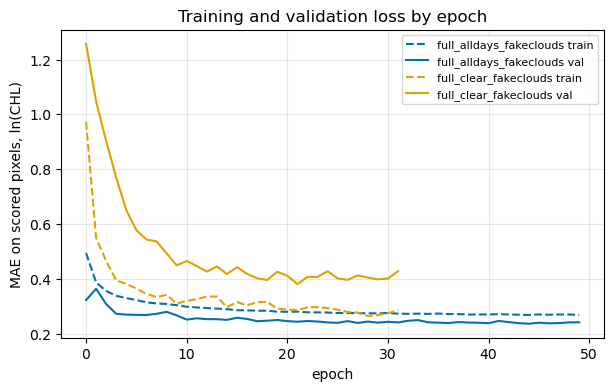

In [10]:
P.plot_history({r: fhist[r] for r in FRUNS}); plt.show()

## Daily MAE on hidden test pixels vs date and vs cloudiness

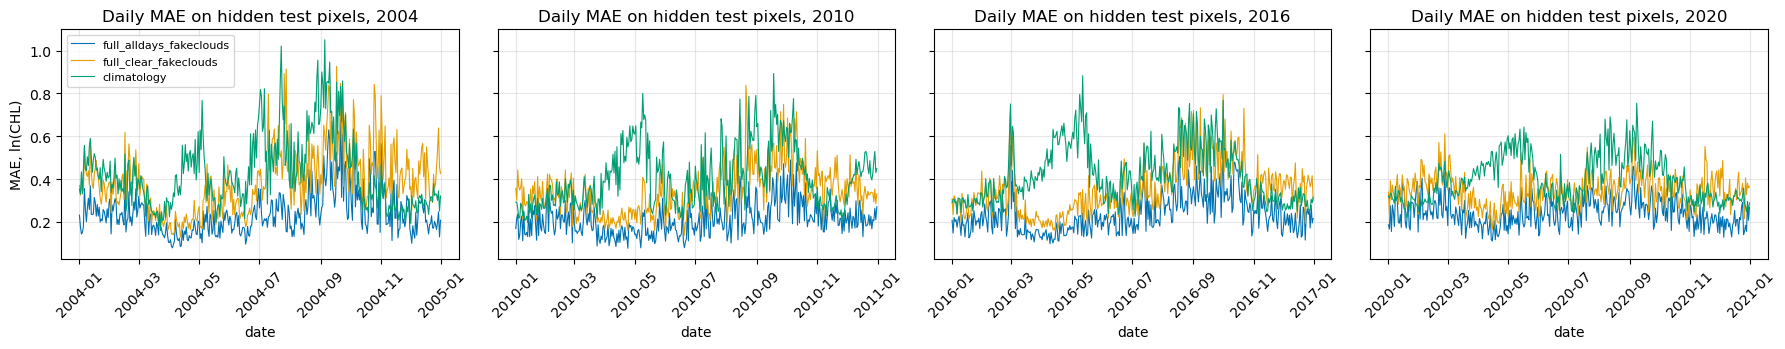

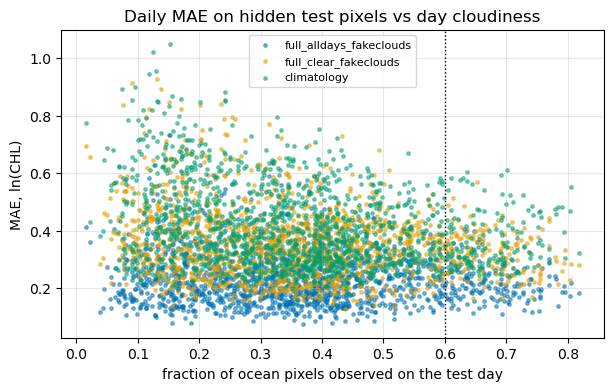

In [11]:
fdaily = {r: np.array([m["mae"] for m in fmet[r]["per_day_test"]]) for r in FRUNS}
fdaily["climatology"] = np.array([metrics(fy_te[k], fclim, fhid_te[k])["mae"] for k in range(len(fte))])
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, yr in zip(axes, sorted(set(fdates_te.year))):
    sel = fdates_te.year == yr
    for name, s in fdaily.items():
        ax.plot(fdates_te[sel], s[sel], lw=.8, label=name)
    ax.set(title=f"Daily MAE on hidden test pixels, {yr}", xlabel="date"); ax.grid(alpha=.3); ax.tick_params(axis="x", labelrotation=45)
axes[0].set_ylabel("MAE, ln(CHL)"); axes[0].legend(fontsize=8); fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for name, s in fdaily.items():
    ax.scatter(fobs_frac, s, s=6, alpha=.5, label=name)
ax.axvline(.6, color="k", ls=":", lw=1)
ax.set(xlabel="fraction of ocean pixels observed on the test day", ylabel="MAE, ln(CHL)", title="Daily MAE on hidden test pixels vs day cloudiness")
ax.grid(alpha=.3); ax.legend(fontsize=8); plt.show()

## Predicted vs true, and MAE by CHL level

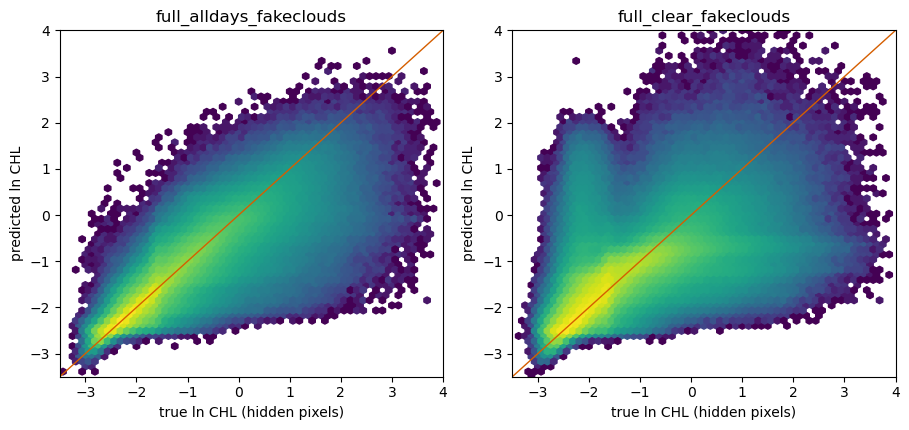

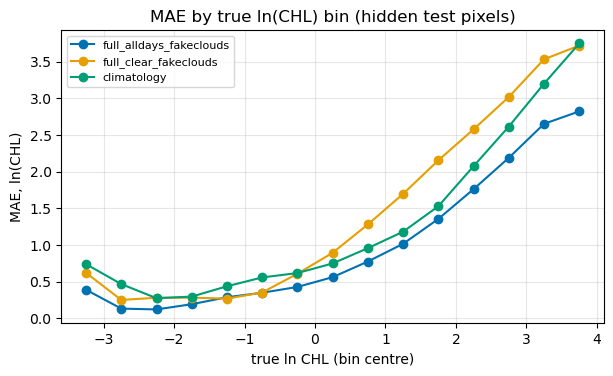

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
bin_centre,-3.25,-2.75,-2.25,-1.75,-1.25,-0.75,-0.25,0.25,0.75,1.25,1.75,2.25,2.75,3.25,3.75
n_pixels,827.00,459049.00,1691084.00,1599562.00,701582.00,463383.00,275232.00,158497.00,90176.00,48868.00,22612.00,8646.00,2720.00,636.00,78.00


In [12]:
fig, axes = plt.subplots(1, len(FRUNS), figsize=(4.6 * len(FRUNS), 4.4))
for ax, r in zip(axes, FRUNS):
    P.plot_scatter(fy_te, fpred_te[r], fhid_te, r, ax=ax)
fig.tight_layout(); plt.show()
fbins = {r: mae_by_bin(fy_te, fpred_te[r], fhid_te, edges) for r in FRUNS}
fbins["climatology"] = mae_by_bin(fy_te, np.broadcast_to(fclim, fy_te.shape), fhid_te, edges)
P.plot_mae_by_bin(fbins); plt.show()
pd.DataFrame({"bin_centre": fbins[FRUNS[0]][0], "n_pixels": fbins[FRUNS[0]][2].astype(int)}).T

## Example test days: one clear, one cloudy

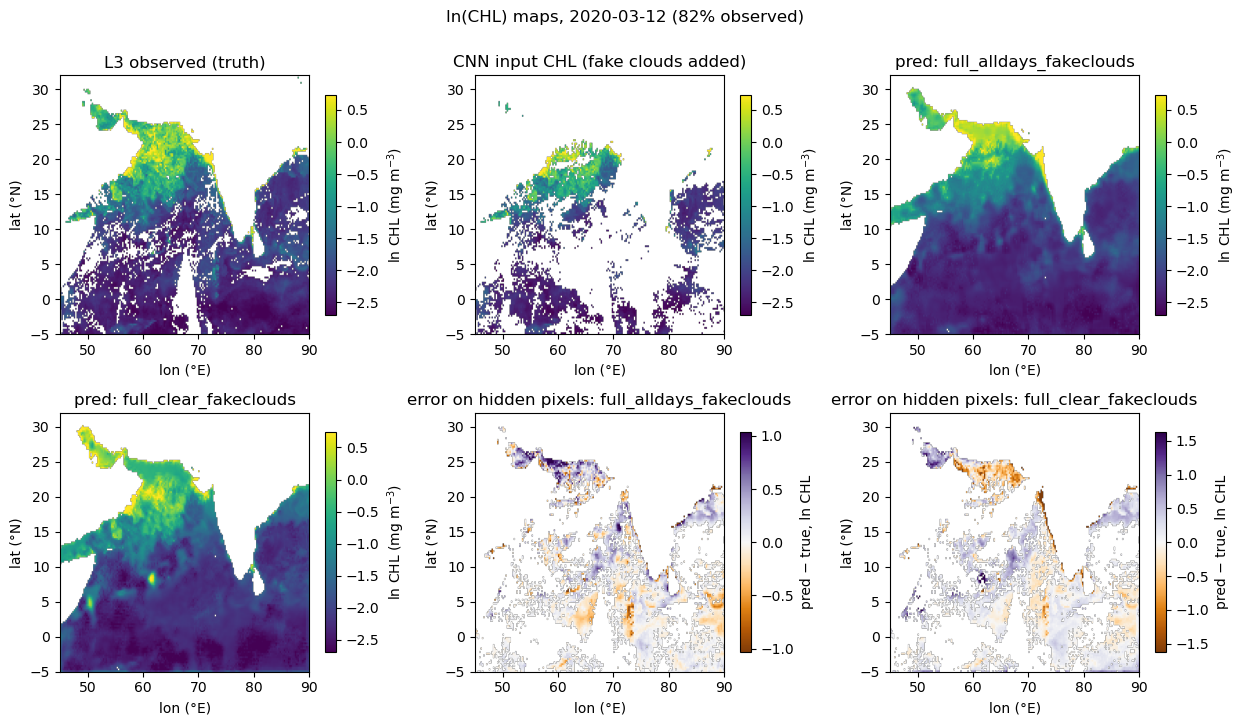

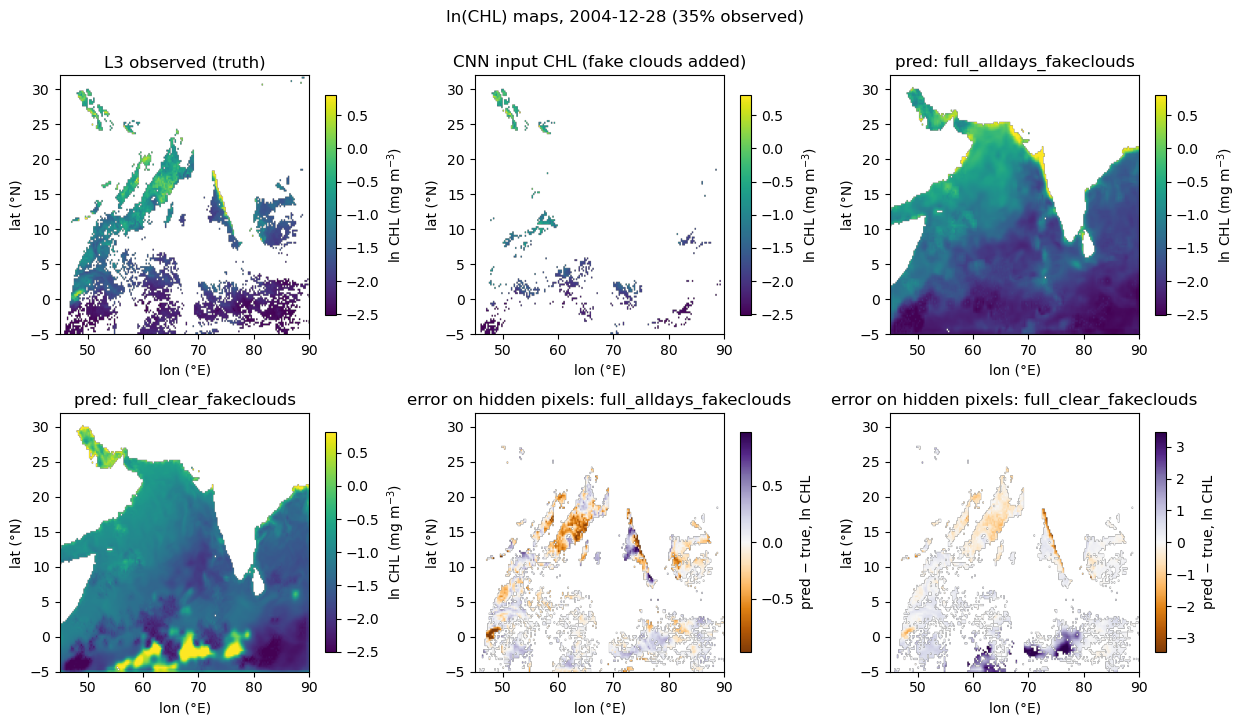

In [13]:
for k in [int(np.argmax(fobs_frac)), int(np.argmin(np.abs(fobs_frac - np.median(fobs_frac))))]:
    date = fdates_te[k].date()
    inp = np.where(fobs_te[k] & ~fhid_te[k], fy_te[k], np.nan)
    panels = {"L3 observed (truth)": fy_te[k], "CNN input CHL (fake clouds added)": inp,
              "pred: full_alldays_fakeclouds": fpred_te["full_alldays_fakeclouds"][k], "pred: full_clear_fakeclouds": fpred_te["full_clear_fakeclouds"][k]}
    err = {f"error on hidden pixels: {r}": np.where(fhid_te[k], fpred_te[r][k] - fy_te[k], np.nan) for r in FRUNS}
    P.plot_day_maps(full["lat"], full["lon"], panels, f"{date} ({fobs_frac[k]:.0%} observed)", err=err, ncols=3); plt.show()